# Лабораторная работа №4. Промпт как программа

**Курс:** Автоматическая обработка текстов

**Автор:** Мещеряков Даниил Павлович, К3440, ИСУ 409130

**Цель:** сделать из LLM-извлечения проверяемый программный компонент: ответ описан схемой, поведение зафиксировано тестами, каждый ответ проходит валидацию, а неподтвержденные текстом извлечения не попадают в результат.

**Что извлекается.** Из отзыва о лекарстве: препараты (drug), показания и симптомы (indication), положительные эффекты (positive_effect), нежелательные реакции (adverse_reaction) и фрагменты текста, на которые опираются эти элементы (evidence).

**Модель.** Qwen3-4B-Instruct-2507 в 4-битном квантовании q4_K_M, локально через Ollama. Температура 0, seed 42, контекст 8192 токена, ответ не длиннее 1024 токенов.

Ноутбук выполняется сверху вниз. Ответы модели на 50 отзывов сохранены в `results/`, и при `RERUN = False` они читаются из файлов, а модель вызывается только в тестах.

In [1]:
import json
import os
import random
import re
import subprocess
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import snowballstemmer

SEED = 409130
N_PER_GROUP = 25
MIN_LEN, MAX_LEN = 300, 1200
SEP = " | "

MODEL = "qwen3:4b-instruct-2507-q4_K_M"
OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://127.0.0.1:11434")
RERUN = False

RAW_URL = "https://raw.githubusercontent.com/cimm-kzn/RuDReC/master/data/rudrec_annotated.json"
RAW_PATH = Path("data/raw/rudrec_annotated.json")
REVIEWS_PATH = Path("data/reviews.csv")
GOLD_PE_PATH = Path("data/gold_positive_effect.csv")
PROMPTS = Path("prompts")
RESULTS = Path("results")
for folder in (RAW_PATH.parent, PROMPTS, RESULTS, Path("tests")):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)

## 1. Данные

В размеченной части RuDReC 500 отзывов, но лежат они по предложениям, и у каждого предложения свой список сущностей. Сначала отзывы собираются обратно. Затем тексты нормализуются: е с точками заменяется на е, длинное и среднее тире на дефис. Дословность evidence дальше проверяется уже по нормализованному тексту. Служебные хвосты корпуса вида «RATING 3 NOTE» оставлены как есть, они встречаются в 8 отзывах выборки.

Эталон для трех полей берется из разметки корпуса: `Drugname` для drug, `DI` для indication, `ADR` для adverse_reaction. Формы выпуска (`Drugform`), группы средств (`Drugclass`) и `Finding` не используются. Корпус размечает каждое упоминание, и одно название часто повторяется в разных падежах («ингавирин» и «Ингавирина»), поэтому одинаковые по основам слов элементы эталона внутри отзыва объединяются.

В выборку попадают отзывы длиной 300-1200 символов: 25 с нежелательной реакцией в разметке и 25 без нее. Без такого деления реакций в выборке было бы мало, и поле adverse_reaction оценивалось бы на нескольких отзывах.

In [2]:
if not RAW_PATH.exists():
    urllib.request.urlretrieve(RAW_URL, RAW_PATH)

GOLD_TYPES = {"Drugname": "drug", "DI": "indication", "ADR": "adverse_reaction"}
REPLACE = ((chr(0x451), chr(0x435)), (chr(0x401), chr(0x415)), (chr(0x2014), "-"), (chr(0x2013), "-"))


def clean(s):
    for a, b in REPLACE:
        s = s.replace(a, b)
    return s


stemmer = snowballstemmer.stemmer("russian")


def unique(items):
    seen, out = set(), []
    for x in items:
        key = " ".join(stemmer.stemWords(re.findall(r"\w+", x.lower()))) or x.lower()
        if key not in seen:
            seen.add(key)
            out.append(x)
    return out


sentences = {}
for line in RAW_PATH.read_text(encoding="utf-8").splitlines():
    if line.strip():
        row = json.loads(line.replace(": NaN", ": null"))
        sentences.setdefault(row["file_name"], []).append(row)

reviews = []
for name in sorted(sentences):
    sents = sorted(sentences[name], key=lambda s: s["sentence_id"])
    text = clean("".join(s["text"] for s in sents).strip())
    gold = {f: [] for f in GOLD_TYPES.values()}
    for s in sents:
        for e in sorted(s["entities"], key=lambda e: e["start"]):
            if e["entity_type"] in GOLD_TYPES:
                gold[GOLD_TYPES[e["entity_type"]]].append(clean(e["entity_text"].strip()))
    reviews.append({"id": name.removesuffix(".tsv"), "text": text, **{f: unique(v) for f, v in gold.items()}})

pool = [r for r in reviews if MIN_LEN <= len(r["text"]) <= MAX_LEN]
with_adr = [r for r in pool if r["adverse_reaction"]]
without_adr = [r for r in pool if not r["adverse_reaction"]]
rng = random.Random(SEED)
sample = rng.sample(with_adr, N_PER_GROUP) + rng.sample(without_adr, N_PER_GROUP)
rng.shuffle(sample)

data = pd.DataFrame([{"id": r["id"], "text": r["text"], **{f: SEP.join(r[f]) for f in GOLD_TYPES.values()}}
                     for r in sample])
data.to_csv(REVIEWS_PATH, index=False, encoding="utf-8")
print(f"отзывов в корпусе: {len(reviews)}, подходят по длине: {len(pool)} "
      f"(с ADR {len(with_adr)}, без ADR {len(without_adr)}), выбрано: {len(data)}")
print("длина отзыва, символов: среднее", round(data["text"].str.len().mean()),
      ", медиана", int(data["text"].str.len().median()))
print("отзывов с хвостом RATING ... NOTE:", data["text"].str.contains("RATING").sum())

отзывов в корпусе: 500, подходят по длине: 451 (с ADR 176, без ADR 275), выбрано: 50
длина отзыва, символов: среднее 713 , медиана 711
отзывов с хвостом RATING ... NOTE: 8


In [3]:
gold_pe = pd.read_csv(GOLD_PE_PATH, dtype=str, keep_default_na=False)
data = data.astype({"id": str}).merge(gold_pe, on="id", how="left", validate="one_to_one")
assert data["positive_effect"].notna().all()
data.to_csv(REVIEWS_PATH, index=False, encoding="utf-8")

GOLD = {f: [[x for x in v.split(SEP) if x] for v in data[f]]
        for f in ("drug", "indication", "positive_effect", "adverse_reaction")}
pd.DataFrame([{"поле": f, "всего элементов": sum(map(len, v)), "отзывов, где поле не пустое": sum(bool(x) for x in v)}
              for f, v in GOLD.items()])

,поле,всего элементов,"отзывов, где поле не пустое"
0,drug,68,44
1,indication,115,41
2,positive_effect,44,27
3,adverse_reaction,88,25


Положительного эффекта в разметке RuDReC нет, поэтому эталон для него (`data/gold_positive_effect.csv`) составлен вручную до первого запуска модели. Определение то же, что в version_2: в эталон попадало улучшение, которое пациент получил после приема, а эффект, который автор отрицает, только ожидает или пересказывает с чужих слов, не размечался. Если конкретное улучшение в отзыве названо, общее «помог» отдельно не записывалось.

## 2. Схема ответа

Формат ответа задан моделью Pydantic 2 `Extraction`. Все пять полей обязательны, каждое это список строк. Неизвестное поле запрещено (`extra="forbid"`), строгий режим (`strict=True`) отключает любые неявные приведения типов, пустая строка в списке считается ошибкой. Ошибки Pydantic переводятся в короткие фразы на русском, они потом уходят модели в повторный запрос.

In [4]:
%%writefile schema.py
from typing import Annotated

from pydantic import BaseModel, ConfigDict, StringConstraints, ValidationError

FIELDS = ("drug", "indication", "positive_effect", "adverse_reaction")
ALL_FIELDS = FIELDS + ("evidence",)

Item = Annotated[str, StringConstraints(strip_whitespace=True, min_length=1)]


class Extraction(BaseModel):
    model_config = ConfigDict(extra="forbid", strict=True)

    drug: list[Item]
    indication: list[Item]
    positive_effect: list[Item]
    adverse_reaction: list[Item]
    evidence: list[Item]


def describe_errors(error: ValidationError) -> list[str]:
    messages = []
    for item in error.errors():
        loc = item["loc"]
        name = loc[0] if loc else ""
        kind = item["type"]
        if kind == "extra_forbidden":
            messages.append(f"лишнее поле «{name}»")
        elif kind == "missing":
            messages.append(f"нет обязательного поля «{name}»")
        elif kind == "list_type":
            messages.append(f"поле «{name}» должно быть списком строк")
        elif kind == "string_type":
            messages.append(f"в поле «{name}» элемент {loc[1]} не строка")
        elif kind == "string_too_short":
            messages.append(f"в поле «{name}» пустая строка")
        elif kind == "model_type":
            messages.append("ответ должен быть JSON-объектом")
        else:
            messages.append(f"поле «{name}»: {item['msg']}")
    return messages

Overwriting schema.py


## 3. Проверка ответа, повтор и сборка результата

`check_response` проверяет ответ модели по шагам:
1. весь ответ должен быть одним JSON-объектом без повторяющихся ключей; обертка в блок кода markdown считается ошибкой;
2. объект проходит схему `Extraction`;
3. каждый фрагмент evidence найден в отзыве дословно: те же буквы, регистр и знаки, фрагмент начинается и кончается на границе слова, а различаться могут только цепочки пробелов и переносов строк между словами. Если фрагмент не найден, в сообщение об ошибке добавляется самый похожий участок отзыва;
4. в каждом элементе есть значимые слова (элемент из одного союза или частицы считается ошибкой);
5. в drug нет элементов только из слов формы выпуска, группы средств и указательных слов («противовирусный препарат», «эти капли»);
6. каждый элемент опирается на найденные фрагменты: хотя бы половина его основ слов (стеммер snowball, частицы «не», «ни», «нет» не считаются) есть в одном фрагменте. Основы совпадают, если они равны, если одна продолжает другую (от 4 букв) или если они от 6 букв и различаются опечаткой.

**Повтор.** Если хоть одна проверка не пройдена, модель получает в том же диалоге свой ответ и список всех ошибок и присылает JSON заново. Повтор задан константой `MAX_RETRIES = 1`, третьего вызова не бывает.

**Сборка результата** (`assemble`). В итог идут элементы обеих попыток. Опора для элемента ищется во всех дословных фрагментах модели из обеих попыток: на повторе модель часто исправляет фрагмент, но сокращает список элементов, и так подтвержденные элементы первой попытки не теряются. Препарат или показание без опоры остается, только если оно само дословно стоит в отзыве: тогда система добавляет в evidence предложение, где оно стоит. Для эффектов и реакций так не делается, потому что для них важен контекст (отрицание, чужой опыт). Один элемент в двух формулировках («заболела правая нога» и «заболела сильно правая нога») берется один раз, для drug только при точном совпадении. Все остальное удаляется. Поэтому любой элемент итогового ответа опирается на дословный фрагмент отзыва, это проверяет `assert` в коде.

Статусы: `valid` (первая попытка без ошибок), `fixed_by_retry` (без ошибок вторая), `cleaned` (во второй тоже ошибки, неподтвержденное удалено), `rejected` (структура сломана в обеих попытках), `empty_text` (пустой текст, модель не вызывается).

In [5]:
%%writefile extractor.py
import difflib
import json
import re
import time
import urllib.request
from dataclasses import dataclass, field
from pathlib import Path

import snowballstemmer
from pydantic import ValidationError

from schema import ALL_FIELDS, FIELDS, Extraction, describe_errors

MAX_RETRIES = 1
PLACEHOLDER = "{{TEXT}}"
GROUNDED_FIELDS = ("drug", "indication")
RETRY_MESSAGE = (
    "Ответ не прошел проверку:\n{errors}\n"
    "Исправь эти ошибки и верни JSON целиком заново: ровно пять полей drug, indication, "
    "positive_effect, adverse_reaction, evidence. Каждый фрагмент evidence скопируй из отзыва "
    "дословно, с тем же регистром букв и теми же опечатками: бери его из ближайшего участка текста, "
    "указанного выше. Элементы, которые в отзыве есть, не удаляй, а добавь для них фрагменты; "
    "убирай только то, чего в отзыве нет. Только JSON."
)
YO, YE = chr(0x451), chr(0x435)


def empty_result():
    return {name: [] for name in ALL_FIELDS}


class OllamaClient:
    def __init__(self, model, url="http://127.0.0.1:11434", options=None, timeout=600):
        self.model = model
        self.url = url.rstrip("/")
        self.options = {"temperature": 0, "seed": 42, "num_ctx": 8192, "num_predict": 1024, **(options or {})}
        self.timeout = timeout
        self._opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))

    def _post(self, path, body):
        request = urllib.request.Request(self.url + path, data=json.dumps(body).encode("utf-8"),
                                         headers={"Content-Type": "application/json"})
        with self._opener.open(request, timeout=self.timeout) as response:
            return json.loads(response.read())

    def available(self):
        try:
            with self._opener.open(self.url + "/api/tags", timeout=5) as response:
                names = [m["name"] for m in json.loads(response.read())["models"]]
            return self.model in names
        except (OSError, ValueError, KeyError):
            return False

    def chat(self, messages):
        started = time.perf_counter()
        reply = self._post("/api/chat", {"model": self.model, "messages": messages, "stream": False,
                                         "keep_alive": "30m", "options": self.options})
        return {"content": reply["message"]["content"],
                "input_tokens": reply.get("prompt_eval_count", 0),
                "output_tokens": reply.get("eval_count", 0),
                "seconds": time.perf_counter() - started}


def load_prompt(path):
    messages = json.loads(Path(path).read_text(encoding="utf-8"))
    assert messages[-1]["role"] == "user" and PLACEHOLDER in messages[-1]["content"]
    return messages


def build_messages(template, text):
    messages = [dict(m) for m in template]
    messages[-1]["content"] = messages[-1]["content"].replace(PLACEHOLDER, text)
    return messages


def _no_duplicate_keys(pairs):
    keys = [key for key, _ in pairs]
    repeated = sorted({key for key in keys if keys.count(key) > 1})
    if repeated:
        raise ValueError("поле «" + "», «".join(repeated) + "» указано дважды")
    return dict(pairs)


def parse_json(raw):
    try:
        value = json.loads(raw.strip(), object_pairs_hook=_no_duplicate_keys)
    except json.JSONDecodeError as error:
        return None, f"ответ не разбирается как JSON ({error.msg}, позиция {error.pos})"
    except ValueError as error:
        return None, f"ответ не разбирается как JSON: {error}"
    if not isinstance(value, dict):
        return None, "ответ должен быть JSON-объектом"
    return value, None


def loose_json(raw):
    """Для анализа version_1: снимает обертку ```json и берет первый объект {...}."""
    value, _ = parse_json(raw)
    if value is not None:
        return value
    start, end = raw.find("{"), raw.rfind("}")
    if start == -1 or end <= start:
        return None
    try:
        value = json.loads(raw[start:end + 1])
    except json.JSONDecodeError:
        return None
    return value if isinstance(value, dict) else None


def find_verbatim(fragment, text):
    """Точная подстрока текста по границам слов; различие допускается только в цепочках пробелов
    и переносов строк между словами."""
    words = fragment.split()
    if not words:
        return None
    pattern = r"\s+".join(map(re.escape, words))
    if re.match(r"\w", words[0]):
        pattern = r"(?<!\w)" + pattern
    if re.search(r"\w$", words[-1]):
        pattern += r"(?!\w)"
    match = re.search(pattern, text)
    return text[match.start():match.end()] if match else None


def sentence_with(fragment, text):
    """Предложение (строка отзыва), в котором фрагмент встречается дословно."""
    exact = find_verbatim(fragment, text)
    if exact is None:
        return None
    start = text.find(exact)
    line_start = text.rfind("\n", 0, start) + 1
    line_end = text.find("\n", start + len(exact))
    return text[line_start:line_end if line_end != -1 else len(text)].strip()


def closest_passage(fragment, text):
    words = list(re.finditer(r"\S+", text))
    n = max(1, len(fragment.split()))
    best, best_score = "", -1.0
    for i in range(len(words)):
        for size in (n - 1, n, n + 1):
            if size < 1 or i + size > len(words):
                continue
            span = text[words[i].start():words[i + size - 1].end()]
            score = difflib.SequenceMatcher(None, fragment.lower(), span.lower()).ratio()
            if score > best_score:
                best, best_score = span, score
    return best


_stemmer = snowballstemmer.stemmer("russian")
STOP_WORDS = {"и", "в", "во", "на", "с", "со", "от", "по", "за", "к", "ко", "у", "о", "об", "из", "для", "при",
              "до", "но", "а", "же", "как", "что", "это", "так", "то", "бы", "ли", "очень", "уже", "я", "мне",
              "меня", "мы", "нам", "нас", "его", "ее", "их", "он", "она", "они", "после", "еще", "все",
              "было", "был", "была", "были", "стало", "стал", "стала"}
NEGATIONS = {"не", "ни", "нет"}


def normalize(value):
    return re.sub(r"\s+", " ", value.lower().replace(YO, YE)).strip(" .,!?;:«»\"'()")


def stems(value):
    tokens = re.findall(r"[a-zа-я0-9]+", value.lower().replace(YO, YE))
    return [_stemmer.stemWord(t) for t in tokens if t not in STOP_WORDS and len(t) > 1]


def content_stems(value):
    return [s for s in stems(value) if s not in NEGATIONS]


def tokens_match(a, b):
    """Совпадение основ: равны, одна продолжает другую (от 4 букв) или отличаются опечаткой (от 6 букв)."""
    if a == b or (min(len(a), len(b)) >= 4 and (a.startswith(b) or b.startswith(a))):
        return True
    return min(len(a), len(b)) >= 6 and difflib.SequenceMatcher(None, a, b).ratio() >= 0.85


def coverage(source, target):
    if not source:
        return 0.0
    return sum(any(tokens_match(s, t) for t in target) for s in source) / len(source)


def similarity(a, b):
    """Близость двух коротких формулировок по основам слов, от 0 до 1."""
    if normalize(a) == normalize(b):
        return 1.0
    sa, sb = stems(a), stems(b)
    if not sa or not sb:
        return 0.0
    return (coverage(sa, sb) * len(sa) + coverage(sb, sa) * len(sb)) / (len(sa) + len(sb))


GENERIC_DRUG_WORDS = ("таблетки таблеток таблетка таблетками капли капель каплями капсулы капсул мазь мази крем "
                      "гель свечи свечей свечами сироп сиропы спрей порошок порошки раствор настойка настойки "
                      "ампулы уколы препарат препараты лекарство лекарства средство средства антибиотик антибиотики "
                      "противовирусный противовирусное противовирусные успокоительный успокоительное "
                      "успокоительные снотворное снотворные иммуномодулятор иммуномодуляторы жаропонижающее "
                      "обезболивающее гомеопатия гомеопатический детский детские успокаивающее седативное "
                      "витамины витаминов вакцина вакцину вакцины иммуностимулятор бальзам леденцы глазные "
                      "назальный сосудосуживающие гормональная этот эта эти этого этой этим этих данный данные "
                      "данного такой такие")
GENERIC_DRUG_STEMS = set(stems(GENERIC_DRUG_WORDS))


def is_generic_drug(item):
    """В элементе только слова формы выпуска, группы средств и указательные слова."""
    item_stems = stems(item)
    return bool(item_stems) and all(s in GENERIC_DRUG_STEMS for s in item_stems)


def is_supported(item, fragments):
    """Элемент подтвержден, если хотя бы половина его основ есть в одном фрагменте evidence.
    Частицы отрицания не считаются: иначе одно "не" подтверждает половину короткого элемента."""
    item_stems = content_stems(item)
    if not item_stems:
        return False
    return any(coverage(item_stems, stems(fragment)) >= 0.5 for fragment in fragments)


def dedupe(values):
    seen, result = set(), []
    for value in values:
        key = normalize(value)
        if key not in seen:
            seen.add(key)
            result.append(value)
    return result


def same_item(name, a, b):
    """Один элемент в двух формулировках: значимые основы одного целиком входят в другой.
    Для drug только точное совпадение: «Кавинтон» и «Кавинтон форте» это разные препараты."""
    if normalize(a) == normalize(b):
        return True
    sa, sb = content_stems(a), content_stems(b)
    return name != "drug" and bool(sa and sb and (coverage(sa, sb) == 1.0 or coverage(sb, sa) == 1.0))


@dataclass
class Check:
    data: dict | None
    errors: list = field(default_factory=list)
    bad_evidence: list = field(default_factory=list)
    unsupported: list = field(default_factory=list)
    invalid_items: list = field(default_factory=list)

    @property
    def structure_ok(self):
        return self.data is not None

    @property
    def ok(self):
        return not self.errors

    @property
    def rejected_items(self):
        return self.invalid_items + self.unsupported


def check_response(raw, text):
    """JSON, схема Pydantic, дословность evidence, значимые слова и названия, опора элементов на evidence."""
    value, error = parse_json(raw)
    if error:
        return Check(None, [error])
    try:
        parsed = Extraction.model_validate(value)
    except ValidationError as validation_error:
        return Check(None, describe_errors(validation_error))
    data = parsed.model_dump()
    errors, found, bad = [], [], []
    for fragment in data["evidence"]:
        exact = find_verbatim(fragment, text)
        if exact is not None:
            found.append(exact)
        elif fragment not in bad:
            bad.append(fragment)
            errors.append(f"фрагмента evidence «{fragment}» нет в тексте дословно; "
                          f"ближайший участок текста: «{closest_passage(fragment, text)}»")
    data = {name: dedupe(data[name]) for name in FIELDS} | {"evidence": dedupe(found)}
    invalid = []
    for name in FIELDS:
        for item in data[name]:
            if not content_stems(item):
                invalid.append((name, item))
                errors.append(f"в элементе «{item}» поля {name} нет значимых слов")
            elif name == "drug" and is_generic_drug(item):
                invalid.append((name, item))
                errors.append(f"«{item}» в поле drug не название препарата, а форма выпуска или группа средств")
    unsupported = [(name, item) for name in FIELDS for item in data[name]
                   if (name, item) not in invalid and not is_supported(item, data["evidence"])]
    for name, item in unsupported:
        errors.append(f"для «{item}» из поля {name} нет подтверждающего фрагмента в evidence")
    return Check(data, errors, bad, unsupported, invalid)


def assemble(checks, text):
    """Итоговый ответ из всех структурно целых попыток, начиная с последней.

    Опора для элемента ищется во всех дословных фрагментах модели из обеих попыток. Препарат или показание
    без опоры остается, только если сам элемент дословно есть в отзыве: тогда в evidence добавляется
    предложение, где он стоит. Остальное удаляется. Один элемент в двух формулировках берется один раз.
    Так каждый элемент ответа опирается на дословный фрагмент отзыва.
    """
    usable = [c for c in checks if c.structure_ok]
    model_evidence = dedupe(e for c in usable for e in c.data["evidence"])
    result, grounded, rejected = empty_result(), [], []
    result["evidence"] = list(model_evidence)
    for check in reversed(usable):
        for name in FIELDS:
            for item in check.data[name]:
                if (name, item) in check.invalid_items:
                    rejected.append((name, item))
                    continue
                sentence = None
                if (name, item) in check.unsupported and not is_supported(item, model_evidence):
                    sentence = sentence_with(item, text) if name in GROUNDED_FIELDS else None
                    if sentence is None:
                        rejected.append((name, item))
                        continue
                if any(same_item(name, item, kept) for kept in result[name]):
                    continue
                result[name].append(item)
                if sentence:
                    result["evidence"].append(sentence)
                    grounded.append((name, item))
    result["evidence"] = dedupe(result["evidence"])
    removed = []
    for name, item in rejected:
        if not any(same_item(name, item, x) for x in result[name] + [r for n, r in removed if n == name]):
            removed.append((name, item))
    assert all(is_supported(item, result["evidence"]) for name in FIELDS for item in result[name])
    return result, removed, grounded


def finalize(checks, text):
    """Статус и итоговый ответ по результатам проверки всех попыток."""
    if not any(c.structure_ok for c in checks):
        return {"status": "rejected", "result": empty_result(), "removed_evidence": [], "removed_items": [],
                "grounded_items": []}
    if checks[-1].ok:
        status = "valid" if len(checks) == 1 else "fixed_by_retry"
    else:
        status = "cleaned"
    result, removed, grounded = assemble(checks, text)
    bad = dedupe(e for c in checks if c.structure_ok for e in c.bad_evidence)
    return {"status": status, "result": result, "removed_evidence": bad if status == "cleaned" else [],
            "removed_items": removed, "grounded_items": grounded}


class Extractor:
    """version_2, проверка ответа и ровно один повторный запрос с описанием ошибок.

    Статусы: valid (первая попытка прошла проверку), fixed_by_retry (прошла вторая), cleaned (вторая тоже
    с ошибками, неподтвержденное удалено), rejected (структура сломана в обеих попытках), empty_text.
    """

    def __init__(self, client, template):
        self.client = client
        self.template = template

    def extract(self, text):
        if not text or not text.strip():
            return {"status": "empty_text", "result": empty_result(), "attempts": [],
                    "removed_evidence": [], "removed_items": [], "grounded_items": []}
        messages = build_messages(self.template, text)
        attempts, checks = [], []
        for attempt in range(1 + MAX_RETRIES):
            reply = self.client.chat(messages)
            check = check_response(reply["content"], text)
            attempts.append({"attempt": attempt + 1, "raw": reply["content"], "errors": check.errors,
                             "input_tokens": reply["input_tokens"], "output_tokens": reply["output_tokens"],
                             "seconds": reply["seconds"]})
            checks.append(check)
            if check.ok:
                break
            errors = "\n".join(f"- {e}" for e in check.errors)
            messages = messages + [{"role": "assistant", "content": reply["content"]},
                                   {"role": "user", "content": RETRY_MESSAGE.format(errors=errors)}]
        return {"attempts": attempts, **finalize(checks, text)}

Overwriting extractor.py


In [6]:
from schema import ALL_FIELDS, FIELDS, Extraction
from extractor import (Extractor, OllamaClient, build_messages, check_response, finalize, find_verbatim,
                       is_generic_drug, is_supported, loose_json, parse_json, similarity)

client = OllamaClient(MODEL, OLLAMA_URL)
print(MODEL, "доступна" if client.available() else "НЕ доступна", "по адресу", OLLAMA_URL)

qwen3:4b-instruct-2507-q4_K_M доступна по адресу http://127.0.0.1:11435


Словарь форм и групп из шага 5 проверен на всем корпусе: какую долю размеченных форм (`Drugform`) и групп (`Drugclass`) он отсеивает и не задевает ли настоящие названия (`Drugname`).

In [7]:
mentions = {t: [] for t in ("Drugname", "Drugform", "Drugclass")}
for sents in sentences.values():
    for s in sents:
        for e in s["entities"]:
            if e["entity_type"] in mentions:
                mentions[e["entity_type"]].append(clean(e["entity_text"].strip()))
coverage_rows = []
for etype, items in mentions.items():
    uniq = sorted({x.lower() for x in items})
    coverage_rows.append({"тип": etype, "упоминаний": len(items),
                          "отсеяно упоминаний": sum(map(is_generic_drug, items)),
                          "уникальных строк": len(uniq), "отсеяно уникальных": sum(map(is_generic_drug, uniq))})
print("названия, которые фильтр считает формой или группой:",
      sorted({x.lower() for x in mentions["Drugname"] if is_generic_drug(x)}))
pd.DataFrame(coverage_rows)

названия, которые фильтр считает формой или группой: ['таблетки']


,тип,упоминаний,отсеяно упоминаний,уникальных строк,отсеяно уникальных
0,Drugname,1043,1,421,1
1,Drugform,836,735,131,67
2,Drugclass,330,253,135,66


## 4. Промпты

**version_1** состоит из одной просьбы извлечь пять полей и пустого шаблона JSON. Определений полей, правил и примеров в нем нет.

**version_2** это системное сообщение с правилами и два размеченных примера в виде пар сообщений user и assistant. В правилах описано каждое поле, кто считается пациентом, как обращаться с отрицаниями, ожиданиями, чужим опытом, цитатами из инструкции и свойствами препарата, и как копировать evidence. Первый пример: два препарата, эффект, реакция и реакция у подруги, которую брать не нужно. Второй: препарат без названия, цитата из инструкции, отрицаемая реакция, эффект, которого не было, и надежда на эффект. Код ниже проверяет, что ответы в примерах проходят схему и их фрагменты дословно есть в текстах примеров.

Оба промпта сохраняются в `prompts/` как списки сообщений для `/api/chat`, отзыв подставляется вместо `{{TEXT}}`.

In [8]:
PROMPT_V1 = [
    {"role": "user",
     "content": "Извлеки из отзыва о лекарстве препарат, показание или симптом, положительный эффект, "
                "нежелательную реакцию и фрагменты текста, подтверждающие извлечение. Ответ дай в формате JSON:\n"
                '{"drug": [], "indication": [], "positive_effect": [], "adverse_reaction": [], "evidence": []}\n\n'
                "Отзыв:\n{{TEXT}}"},
]

RULES_V2 = """Ты извлекаешь сведения из русскоязычного отзыва о лекарстве. Верни один JSON-объект ровно с пятью полями: drug, indication, positive_effect, adverse_reaction, evidence. Значение каждого поля это список строк, возможно пустой. Других полей не добавляй.

Поля:
- drug: собственные названия препаратов из отзыва, в том числе из перечней, сравнений и состава. Название пиши так, как оно написано в тексте, даже с опечаткой. Не являются названием: форма выпуска (таблетки, мазь, свечи, капли, сироп), группа препаратов (антибиотик, противовирусное, успокоительное), слова «препарат», «лекарство», «средство». Сочетание группы и формы без названия («противовирусные таблетки», «детский сироп») тоже не название. Если в отзыве нет ни одного названия, drug пустой.
- indication: болезни, симптомы и цели, ради которых пациент принимал препарат (насморк, бессонница, профилактика гриппа).
- positive_effect: улучшения, которые действительно наступили у пациента после приема (спала температура, быстрее уснул). Если конкретное улучшение не названо, но автор пишет, что препарат помог, запиши эту общую фразу.
- adverse_reaction: нежелательные реакции и ухудшения, которые возникли у пациента после приема (тошнота, сыпь, головная боль).
- evidence: фрагменты отзыва, подтверждающие извлечение. Для каждого элемента других полей нужен короткий фрагмент из 2-10 слов, в котором этот элемент упомянут. Один фрагмент может подтверждать несколько элементов.

Пациент: автор отзыва или человек, которого автор сам лечил в этом отзыве (ребенок, муж, мама).

Правила:
1. Отрицаемый эффект или реакция не записываются: «не помог», «легче не стало», «побочных эффектов не было». Отрицание может стоять в конце фразы и относится ко всей фразе: «кашель так и не стал мягче» значит, что эффекта нет. Исключение: если после приема отрицается сама болезнь («ни разу не заболели», «температура больше не поднималась»), это positive_effect.
2. Ожидаемое, предполагаемое и обещанное не записывается в positive_effect и adverse_reaction: «надеюсь, пройдет», «должен снять отек», «наверное, поможет».
3. Опыт других людей (подруги, коллеги, знакомых, авторов других отзывов) к пациенту не относится, их эффекты и реакции не записываются.
4. Цитаты из инструкции, рекламы и слова врача о возможных эффектах не являются наблюдениями, их не записывай в positive_effect и adverse_reaction.
5. Вкус, запах, цена, упаковка и удобство приема являются свойствами препарата, а не эффектом.
6. Элементы полей пиши короткими формулировками из текста, без пересказа и без повторов.
7. Каждый фрагмент evidence копируй из отзыва символ в символ: тот же регистр, те же опечатки, кавычки и знаки препинания. Бери короткий кусок вокруг упоминания, а не предложение целиком, и не склеивай куски разных предложений.

Ответ: только JSON, без пояснений и без разметки markdown."""

EXAMPLES_V2 = [
    ("При гриппе врач выписал мне Ингаверин и Арбидол. Уже на второй день спала температура, но появилась "
     "тошнота. Подруга говорила, что у нее от Арбидола болела голова.",
     {"drug": ["Ингаверин", "Арбидол"], "indication": ["гриппе"], "positive_effect": ["спала температура"],
      "adverse_reaction": ["тошнота"],
      "evidence": ["При гриппе врач выписал мне Ингаверин и Арбидол", "Уже на второй день спала температура",
                   "появилась тошнота"]}),
    ("Ребенку дали сироп от кашля, название на упаковке стерлось. В инструкции пугают сонливостью и аллергией, "
     "но у нас ничего подобного не было. Кашель за неделю так и не прошел, надеюсь, что следующее лекарство "
     "подействует лучше.",
     {"drug": [], "indication": ["кашля"], "positive_effect": [], "adverse_reaction": [],
      "evidence": ["Ребенку дали сироп от кашля"]}),
]

PROMPT_V2 = [{"role": "system", "content": RULES_V2}]
for example_text, example_answer in EXAMPLES_V2:
    Extraction.model_validate(example_answer)
    assert all(find_verbatim(fragment, example_text) for fragment in example_answer["evidence"])
    PROMPT_V2 += [{"role": "user", "content": "Отзыв:\n" + example_text},
                  {"role": "assistant", "content": json.dumps(example_answer, ensure_ascii=False)}]
PROMPT_V2.append({"role": "user", "content": "Отзыв:\n{{TEXT}}"})

for name, messages in [("version_1", PROMPT_V1), ("version_2", PROMPT_V2)]:
    (PROMPTS / f"{name}.txt").write_text(json.dumps(messages, ensure_ascii=False, indent=2), encoding="utf-8")
print("version_1:", len(PROMPT_V1), "сообщение,", len(PROMPT_V1[0]["content"]), "символов")
print("version_2:", len(PROMPT_V2), "сообщений, правила", len(RULES_V2), "символов, с примерами",
      sum(len(m["content"]) for m in PROMPT_V2) - len("{{TEXT}}"), "символов, примеров", len(EXAMPLES_V2))

version_1: 1 сообщение, 290 символов
version_2: 6 сообщений, правила 2828 символов, с примерами 3627 символов, примеров 2


## 5. Тесты

В `tests/test_extractor.py` 26 тестов. Первые десять повторяют обязательный перечень из задания. В случаях 2-8 работает настоящая модель с итоговой системой (пометка `llm`; если Ollama нет, они пропускаются). Для случаев 9 и 10 нужен заведомо плохой ответ, которого модель по просьбе не даст, поэтому там, как и в случае 1, вместо модели стоит заглушка `FakeClient` с заготовленными ответами. Остальные 16 тестов проверяют схему, проверку и сборку результата без модели.

Тексты тестов придуманы под каждый случай, их нет ни в выборке, ни в примерах промпта. Тесты с моделью проверяют не только то, чего не должно быть, но и то, что должно извлечься: например, в случае «эффект отрицается» препарат должен найтись, а positive_effect остаться пустым.

Тесты запускаются три раза подряд: при температуре 0 и фиксированном seed ответы модели все равно не полностью детерминированы, вероятная причина в кэше общего начала промпта в Ollama.

In [9]:
%%writefile pytest.ini
[pytest]
testpaths = tests
pythonpath = .
markers =
    llm: тест обращается к локальной модели через Ollama

Overwriting pytest.ini


In [10]:
%%writefile tests/test_extractor.py
import json
import os
from pathlib import Path

import pytest
from pydantic import ValidationError

from extractor import Extractor, OllamaClient, check_response, find_verbatim, load_prompt, parse_json, similarity
from schema import Extraction

MODEL = os.environ.get("LAB4_MODEL", "qwen3:4b-instruct-2507-q4_K_M")
OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://127.0.0.1:11434")
PROMPT_V2 = Path(__file__).parent.parent / "prompts" / "version_2.txt"
BARE_PROMPT = [{"role": "user", "content": "{{TEXT}}"}]


class FakeClient:
    """Подставная LLM: по очереди отдает заранее заданные ответы и запоминает запросы."""

    def __init__(self, *replies):
        self.replies = list(replies)
        self.calls = []

    def chat(self, messages):
        self.calls.append(messages)
        content = self.replies.pop(0)
        if not isinstance(content, str):
            content = json.dumps(content, ensure_ascii=False)
        return {"content": content, "input_tokens": 0, "output_tokens": 0, "seconds": 0.0}


def answer(**fields):
    base = {"drug": [], "indication": [], "positive_effect": [], "adverse_reaction": [], "evidence": []}
    base.update(fields)
    return base


def check_of(text, **fields):
    return check_response(json.dumps(answer(**fields), ensure_ascii=False), text)


@pytest.fixture(scope="module")
def llm():
    client = OllamaClient(MODEL, OLLAMA_URL)
    if not PROMPT_V2.exists():
        pytest.skip(f"нет файла промпта {PROMPT_V2}")
    if not client.available():
        pytest.skip(f"Ollama с моделью {MODEL} недоступна по адресу {OLLAMA_URL}")
    return Extractor(client, load_prompt(PROMPT_V2))


def contains(items, expected):
    return any(similarity(item, expected) >= 0.5 for item in items)


def test_01_empty_text():
    client = FakeClient()
    for text in ["", "   \n "]:
        out = Extractor(client, BARE_PROMPT).extract(text)
        assert out["status"] == "empty_text"
        assert out["result"] == answer()
    assert client.calls == []


@pytest.mark.llm
def test_02_drug_not_named(llm):
    out = llm.extract("Купила в аптеке успокоительные капли, название уже не помню. "
                      "Пила их перед сном неделю, засыпать стала быстрее.")
    assert out["status"] != "rejected"
    assert out["result"]["drug"] == []
    assert contains(out["result"]["positive_effect"], "засыпать стала быстрее")


@pytest.mark.llm
def test_03_several_drugs(llm):
    out = llm.extract("От бронхита пульмонолог выписал Флемоксин, на ночь я пила Синупрет, а кашель снимала "
                      "Лазолваном. Через неделю кашель прошел.")
    drugs = out["result"]["drug"]
    assert all(contains(drugs, name) for name in ["Флемоксин", "Синупрет", "Лазолван"])


@pytest.mark.llm
def test_04_effect_negated(llm):
    out = llm.extract("Неделю принимала Персен перед экзаменами. Волнение никуда не делось, "
                      "и уснуть по-прежнему было трудно.")
    assert out["status"] != "rejected"
    assert contains(out["result"]["drug"], "Персен")
    assert out["result"]["positive_effect"] == []


@pytest.mark.llm
def test_05_effect_supposed(llm):
    out = llm.extract("Сегодня начали давать сыну Эреспал от кашля. Думаю, через пару дней кашель станет мягче.")
    assert out["status"] != "rejected"
    assert contains(out["result"]["drug"], "Эреспал")
    assert out["result"]["positive_effect"] == []
    assert out["result"]["adverse_reaction"] == []


@pytest.mark.llm
def test_06_reaction_of_other_person(llm):
    out = llm.extract("Пью Но-шпу при болях в животе, мне она помогает быстро. А у коллеги от нее кружилась "
                      "голова, поэтому он ее больше не покупает.")
    assert out["status"] != "rejected"
    assert out["result"]["adverse_reaction"] == []
    assert out["result"]["positive_effect"] != []


@pytest.mark.llm
def test_07_text_with_quote(llm):
    text = ("Лечила цистит Монуралом. В аннотации сказано: «возможны диарея, тошнота и изжога». "
            "На следующий день стало легче.")
    out = llm.extract(text)
    assert out["status"] != "rejected"
    assert out["result"]["adverse_reaction"] == []
    assert contains(out["result"]["positive_effect"], "стало легче")


@pytest.mark.llm
def test_08_misspelled_name(llm):
    out = llm.extract("Пила Нурафен от головной боли, через полчаса боль прошла.")
    assert "Нурафен" in out["result"]["drug"]


def test_09_extra_field_then_fixed():
    text = "Пила Нурофен от зубной боли, через полчаса боль прошла."
    good = answer(drug=["Нурофен"], indication=["зубной боли"], positive_effect=["боль прошла"],
                  evidence=["Пила Нурофен от зубной боли", "через полчаса боль прошла"])
    client = FakeClient({**good, "dosage": "1 таблетка"}, good)
    out = Extractor(client, BARE_PROMPT).extract(text)
    assert len(client.calls) == 2
    assert "лишнее поле «dosage»" in client.calls[1][-1]["content"]
    assert out["status"] == "fixed_by_retry"
    assert out["result"] == good


def test_10_evidence_not_in_text_only_one_retry():
    text = "Принимала Афобазол месяц, стала спокойнее."
    invented = answer(drug=["Афобазол"], positive_effect=["тревога ушла"],
                      evidence=["Принимала Афобазол месяц", "тревога полностью ушла"])
    client = FakeClient(invented, invented, invented)
    out = Extractor(client, BARE_PROMPT).extract(text)
    assert len(client.calls) == 2
    retry = client.calls[1][-1]["content"]
    assert "«тревога полностью ушла» нет в тексте" in retry and "ближайший участок текста" in retry
    assert out["status"] == "cleaned"
    assert out["result"]["evidence"] == ["Принимала Афобазол месяц"]
    assert out["result"]["drug"] == ["Афобазол"] and out["result"]["positive_effect"] == []
    assert out["removed_items"] == [("positive_effect", "тревога ушла")]


def test_schema_rejects_missing_field_and_wrong_types():
    with pytest.raises(ValidationError):
        Extraction.model_validate({"drug": [], "indication": [], "positive_effect": [], "adverse_reaction": []})
    with pytest.raises(ValidationError):
        Extraction.model_validate(answer(drug="Нурофен"))
    with pytest.raises(ValidationError):
        Extraction.model_validate(answer(drug=[1]))
    with pytest.raises(ValidationError):
        Extraction.model_validate(answer(drug=["  "]))


def test_duplicate_key_is_an_error():
    value, error = parse_json('{"drug": ["Нурофен"], "drug": [], "indication": [], "positive_effect": [], '
                              '"adverse_reaction": [], "evidence": []}')
    assert value is None and "«drug» указано дважды" in error


def test_invalid_json_gets_one_retry():
    text = "Капала Називин, нос задышал."
    good = answer(drug=["Називин"], positive_effect=["нос задышал"], evidence=["Капала Називин, нос задышал"])
    client = FakeClient('```json\n{"drug": ["Називин"]}\n```', good)
    out = Extractor(client, BARE_PROMPT).extract(text)
    assert len(client.calls) == 2 and "не разбирается как JSON" in client.calls[1][-1]["content"]
    assert out["status"] == "fixed_by_retry"


def test_broken_structure_twice_is_rejected():
    client = FakeClient("drug: Називин", {"drug": "Називин"})
    out = Extractor(client, BARE_PROMPT).extract("Капала Називин.")
    assert len(client.calls) == 2
    assert out["status"] == "rejected" and out["result"] == answer()


def test_valid_answer_needs_no_retry():
    text = "Пила Нурофен от зубной боли, через полчаса боль прошла."
    good = answer(drug=["Нурофен"], indication=["зубной боли"], positive_effect=["боль прошла"],
                  evidence=["Пила Нурофен от зубной боли", "через полчаса боль прошла"])
    client = FakeClient(good)
    out = Extractor(client, BARE_PROMPT).extract(text)
    assert len(client.calls) == 1 and out["status"] == "valid"


def test_verbatim_search_allows_only_whitespace_differences():
    text = "Пила Нурофен от зубной\nболи. Через полчаса боль прошла."
    assert find_verbatim("от зубной боли", text) == "от зубной\nболи"
    assert find_verbatim("Через  полчаса боль прошла", text) == "Через полчаса боль прошла"
    assert find_verbatim("через полчаса боль прошла", text) is None
    assert find_verbatim("боль быстро прошла", text) is None


def test_verbatim_fragment_must_not_cut_words():
    text = "Пила Нурофен от зубной боли."
    assert find_verbatim("урофен от зуб", text) is None
    assert find_verbatim("а", text) is None
    assert find_verbatim("Нурофен от зубной боли.", text) == "Нурофен от зубной боли."


def test_item_without_evidence_is_unsupported():
    check = check_of("Пила Нурофен от зубной боли, через полчаса боль прошла.",
                     drug=["Нурофен"], adverse_reaction=["тошнота"], evidence=["Пила Нурофен"])
    assert check.structure_ok and not check.ok
    assert check.unsupported == [("adverse_reaction", "тошнота")]


def test_item_without_meaningful_words_is_rejected():
    check = check_of("Покупала не только эти. А на обратной стороне расписан прием.",
                     drug=["А"], evidence=["Покупала не только эти"])
    assert check.invalid_items == [("drug", "А")]
    assert "нет значимых слов" in check.errors[0]


def test_drug_form_or_class_is_not_a_name():
    check = check_of("Купила противовирусные таблетки Арбидол.",
                     drug=["противовирусные таблетки", "Арбидол", "эти капли"],
                     evidence=["Купила противовирусные таблетки Арбидол"])
    assert check.invalid_items == [("drug", "противовирусные таблетки"), ("drug", "эти капли")]
    assert "не название препарата" in check.errors[0]


def test_negation_alone_does_not_support_item():
    check = check_of("Сын постоянно болел, и не успевал выздороветь. Начали давать Анаферон.",
                     drug=["Анаферон"], positive_effect=["болезнь сына не повторялась"],
                     evidence=["Сын постоянно болел, и не успевал выздороветь", "Начали давать Анаферон"])
    assert check.unsupported == [("positive_effect", "болезнь сына не повторялась")]


def test_item_with_corrected_typo_is_supported():
    check = check_of("Мучила бессоница, врач выписал Донормил.",
                     drug=["Донормил"], indication=["бессонница"], evidence=["Мучила бессоница", "врач выписал Донормил"])
    assert check.ok


def test_verified_items_of_first_attempt_are_kept():
    text = "Пила Нурофен от зубной боли.\nЧерез полчаса боль прошла."
    first = answer(drug=["Нурофен"], positive_effect=["боль прошла"], adverse_reaction=["тошнота"],
                   evidence=["Пила Нурофен", "Через полчаса боль прошла"])
    second = answer(drug=["Нурофен"], evidence=["Пила Нурофен"])
    out = Extractor(FakeClient(first, second), BARE_PROMPT).extract(text)
    assert out["status"] == "fixed_by_retry"
    assert out["result"]["positive_effect"] == ["боль прошла"]
    assert out["result"]["adverse_reaction"] == []
    assert out["removed_items"] == [("adverse_reaction", "тошнота")]


def test_item_supported_by_fragment_of_other_attempt():
    text = "Четвертый день тошнота, рвота и озноб после приема Донормила."
    first = answer(drug=["Донормил"], adverse_reaction=["тошнота", "рвота", "озноб"],
                   evidence=["четвертый день тошнота", "после приема Донормила"])
    second = answer(drug=["Донормил"], adverse_reaction=["тошнота"],
                    evidence=["Четвертый день тошнота, рвота и озноб", "после приема Донормила"])
    out = Extractor(FakeClient(first, second), BARE_PROMPT).extract(text)
    assert out["status"] == "fixed_by_retry"
    assert out["result"]["adverse_reaction"] == ["тошнота", "рвота", "озноб"]


def test_same_item_from_two_attempts_is_kept_once():
    text = "Пил Кавинтон, потом Кавинтон форте.\nЗаболела сильно правая нога."
    first = answer(drug=["Кавинтон", "Кавинтон форте"], adverse_reaction=["заболела правая нога", "тошнота"],
                   evidence=["Пил Кавинтон, потом Кавинтон форте", "Заболела сильно правая нога"])
    second = answer(drug=["Кавинтон", "Кавинтон форте"], adverse_reaction=["заболела сильно правая нога"],
                    evidence=["Пил Кавинтон, потом Кавинтон форте", "Заболела сильно правая нога"])
    out = Extractor(FakeClient(first, second), BARE_PROMPT).extract(text)
    assert out["status"] == "fixed_by_retry"
    assert out["result"]["drug"] == ["Кавинтон", "Кавинтон форте"]
    assert out["result"]["adverse_reaction"] == ["заболела сильно правая нога"]


def test_drug_without_fragment_is_grounded_in_text_but_effect_is_not():
    text = "Врач посоветовал Лемсип.\nПроходит головная боль."
    bad = answer(drug=["Лемсип"], indication=["гриппе"], positive_effect=["проходит головная боль"],
                 evidence=["Врач посоветовал"])
    out = Extractor(FakeClient(bad, bad), BARE_PROMPT).extract(text)
    assert out["status"] == "cleaned"
    assert out["result"]["drug"] == ["Лемсип"] and "Врач посоветовал Лемсип." in out["result"]["evidence"]
    assert out["grounded_items"] == [("drug", "Лемсип")]
    assert out["result"]["indication"] == [] and out["result"]["positive_effect"] == []

Overwriting tests/test_extractor.py


In [11]:
logs = []
for run in range(1, 4):
    proc = subprocess.run([sys.executable, "-m", "pytest", "-v", "--no-header", "--color=no", "-p", "no:cacheprovider"],
                          capture_output=True, text=True, encoding="utf-8",
                          env={**os.environ, "OLLAMA_URL": OLLAMA_URL, "LAB4_MODEL": MODEL, "PYTHONIOENCODING": "utf-8"})
    logs.append(f"=== запуск {run}\n{proc.stdout}")
    print(f"запуск {run}:", proc.stdout.strip().splitlines()[-1].strip("= "))
(RESULTS / "pytest.log").write_text("\n".join(logs), encoding="utf-8")
print()
print(proc.stdout)

запуск 1: 26 passed in 14.20s


запуск 2: 26 passed in 14.07s


запуск 3: 26 passed in 14.22s

============================= test session starts =============================
collecting ... collected 26 items

tests/test_extractor.py::test_01_empty_text PASSED                       [  3%]
tests/test_extractor.py::test_02_drug_not_named PASSED                   [  7%]
tests/test_extractor.py::test_03_several_drugs PASSED                    [ 11%]
tests/test_extractor.py::test_04_effect_negated PASSED                   [ 15%]
tests/test_extractor.py::test_05_effect_supposed PASSED                  [ 19%]
tests/test_extractor.py::test_06_reaction_of_other_person PASSED         [ 23%]
tests/test_extractor.py::test_07_text_with_quote PASSED                  [ 26%]
tests/test_extractor.py::test_08_misspelled_name PASSED                  [ 30%]
tests/test_extractor.py::test_09_extra_field_then_fixed PASSED           [ 34%]
tests/test_extractor.py::test_10_evidence_not_in_text_only_one_retry PASSED [ 38%]
tests/test_extractor.py::test_schema_rejects_missin

## 6. Прогон на 50 отзывах

version_1 вызывается один раз на отзыв. Итоговая система это version_2, проверка, не больше одного повтора и сборка результата. Сырые ответы, ошибки проверки по попыткам, токены и время пишутся в `results/raw_version_1.jsonl` и `results/raw_final.jsonl`. Токены берутся из ответа Ollama (`prompt_eval_count`, `eval_count`), время меряется в клиенте.

**История прогонов.** Итоговая система прогонялась три раза, ранние прогоны сохранены в `results/dev_runs/` вместе с промптом и логом тестов того момента.
- После run1: тест 2 оказался нестабильным (модель писала в drug «успокоительные капли»), модель портила слова при копировании длинных фрагментов, а частица «не» помогала выдуманному эффекту пройти проверку опоры. В version_2 добавлены правило о сочетании группы и формы и требование коротких фрагментов, в сообщение повтора добавлена просьба брать фрагмент из подсказанного участка с тем же регистром, в проверку добавлены фильтр форм и групп, совпадение основ с опечаткой и исключение частиц отрицания.
- После run2 код прошел независимую проверку. Найдено: элемент без значимых слов (союз «А» в drug) проходил проверку опоры, фрагмент мог обрываться посреди слова, повтор терял подтвержденные элементы первой попытки, а очистка удаляла верные названия, которые есть в тексте. Это исправлено (шаги 3-5 и сборка результата выше). Пример в правиле drug совпадал с текстом теста 2 и заменен, в правило отрицаний добавлен случай с отрицанием в конце фразы, в сообщение повтора добавлена просьба не удалять элементы, которые в отзыве есть. Тесты переписаны: в тестах с моделью добавлены проверки того, что должно извлечься, тексты тестов 3, 4, 7 и 8 заменены, добавлены тесты на новые правила.

version_1 и ее ответы ни разу не менялись. Правки делались по разбору тех же 50 отзывов, на которых система оценивается, это ограничение работы.

In [12]:
def run_or_load(path, run):
    if path.exists() and not RERUN:
        return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines()]
    rows = []
    with path.open("w", encoding="utf-8") as f:
        for i, r in enumerate(data.itertuples(), 1):
            row = {"id": r.id, **run(r.text)}
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
            f.flush()
            rows.append(row)
            if i % 10 == 0:
                print(f"{path.name}: {i}/{len(data)}")
    return rows


def run_v1(text):
    return client.chat(build_messages(PROMPT_V1, text))


extractor = Extractor(client, PROMPT_V2)
raw_v1 = run_or_load(RESULTS / "raw_version_1.jsonl", run_v1)
raw_final = run_or_load(RESULTS / "raw_final.jsonl", extractor.extract)
print(Counter(r["status"] for r in raw_final))

Counter({'cleaned': 25, 'fixed_by_retry': 21, 'valid': 4})


Сборка результата уточнялась уже после финального прогона, по разбору ошибок: одинаковые по смыслу элементы двух попыток больше не дублируются, а опора ищется во фрагментах обеих попыток. Вызовы модели от сборки не зависят, поэтому итоговые ответы пересобраны тем же кодом из сохраненных попыток. Ячейка ниже повторяет проверку всех сохраненных ответов модели текущим кодом и сверяет ошибки, статусы и итоговые ответы с файлом.

In [13]:
text_by_id = dict(zip(data["id"], data["text"]))
for r in raw_final:
    checks = [check_response(a["raw"], text_by_id[r["id"]]) for a in r["attempts"]]
    assert [c.errors for c in checks] == [a["errors"] for a in r["attempts"]], r["id"]
    replay = finalize(checks, text_by_id[r["id"]])
    assert replay["status"] == r["status"] and replay["result"] == r["result"], r["id"]
print("ошибки проверки, статусы и итоговые ответы совпадают с пересчетом для всех", len(raw_final), "отзывов")

ошибки проверки, статусы и итоговые ответы совпадают с пересчетом для всех 50 отзывов


## 7. Сравнение version_1 и итоговой системы

Задание требует сравнить системы по валидности JSON, качеству извлечения и числу неподтвержденных результатов. Сравниваются три столбца:
- **version_1**: ответ на простой промпт как есть;
- **version_2, первая попытка**: первый ответ итоговой системы до проверки, он показывает вклад самого промпта;
- **итоговая система**: version_2, проверка, повтор и сборка результата.

**Валидность JSON**: строгий разбор, разбор после снятия обертки, схема Pydantic и все проверки сразу. Ответы version_1 оцениваются по содержанию, даже если не прошли схему: JSON достается из обертки, строка вместо списка считается списком из одного элемента.

**Неподтвержденные результаты**: фрагменты evidence, которых нет в тексте; элементы без опоры в дословных фрагментах; элементы, которых нет в самом тексте (то же правило опоры, но по всему отзыву). У итоговой системы эти счетчики нулевые по построению, это гарантия механизма. Как часто модель сама дает подтвержденный ответ, видно в строке «Проходит все проверки без очистки» и в столбце первой попытки.

**Качество извлечения.** Элемент ответа засчитывается, если его близость к элементу эталона по основам слов не меньше 0,5 (`similarity`: доля общих основ, усредненная по обоим элементам). Каждый элемент эталона засчитывается не больше одного раза, пары внутри отзыва подбираются жадно, от самых похожих. Precision, recall и F1 даны по каждому полю и общие (micro). Evidence в метриках качества не участвует.

In [14]:
THRESHOLD = 0.5
texts = dict(zip(data["id"], data["text"]))
gold_by_id = {rid: {f: GOLD[f][i] for f in FIELDS} for i, rid in enumerate(data["id"])}


def as_list(value):
    if isinstance(value, str):
        return [value.strip()] if value.strip() else []
    if isinstance(value, list):
        return [str(x).strip() for x in value if str(x).strip()]
    return []


def answer_fields(raw):
    value = loose_json(raw) or {}
    return {f: as_list(value.get(f)) for f in ALL_FIELDS}


def schema_ok(raw):
    value, _ = parse_json(raw)
    try:
        Extraction.model_validate(value)
        return True
    except Exception:
        return False


def audit(pred, text):
    found = [e for e in pred["evidence"] if find_verbatim(e, text)]
    items = [x for f in FIELDS for x in pred[f]]
    return {"evidence": len(pred["evidence"]), "bad_evidence": len(pred["evidence"]) - len(found),
            "items": len(items), "unsupported": sum(not is_supported(x, found) for x in items),
            "not_in_text": sum(not is_supported(x, [text]) for x in items)}


def from_reply(rid, raw, tokens_in, tokens_out, seconds):
    return {"id": rid, "pred": answer_fields(raw), "json_strict": parse_json(raw)[1] is None,
            "json_loose": loose_json(raw) is not None, "schema": schema_ok(raw),
            "all_checks": check_response(raw, texts[rid]).ok, "status": "", "input_tokens": tokens_in,
            "output_tokens": tokens_out, "seconds": seconds, "attempts": 1}


def final_system(raw_rows):
    return [{"id": r["id"], "pred": r["result"], "json_strict": r["status"] != "rejected",
             "json_loose": r["status"] != "rejected", "schema": r["status"] != "rejected",
             "all_checks": r["status"] in ("valid", "fixed_by_retry"), "status": r["status"],
             "input_tokens": sum(a["input_tokens"] for a in r["attempts"]),
             "output_tokens": sum(a["output_tokens"] for a in r["attempts"]),
             "seconds": sum(a["seconds"] for a in r["attempts"]), "attempts": len(r["attempts"]),
             **audit(r["result"], texts[r["id"]])}
            for r in raw_rows]


systems = {
    "version_1": [from_reply(r["id"], r["content"], r["input_tokens"], r["output_tokens"], r["seconds"])
                  for r in raw_v1],
    "version_2, первая попытка": [from_reply(r["id"], r["attempts"][0]["raw"], r["attempts"][0]["input_tokens"],
                                             r["attempts"][0]["output_tokens"], r["attempts"][0]["seconds"])
                                  for r in raw_final],
    "итоговая система": final_system(raw_final),
}
for rows in systems.values():
    for row in rows:
        row.update(audit(row["pred"], texts[row["id"]]))


def match(pred, gold, threshold=THRESHOLD):
    pairs = sorted(((similarity(p, g), i, j) for i, p in enumerate(pred) for j, g in enumerate(gold)), reverse=True)
    used_p, used_g = set(), set()
    for score, i, j in pairs:
        if score < threshold:
            break
        if i not in used_p and j not in used_g:
            used_p.add(i)
            used_g.add(j)
    return used_p, used_g


def prf(tp, n_pred, n_gold):
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def quality(rows, threshold=THRESHOLD, gold=None):
    gold = gold or gold_by_id
    counts = {f: [0, 0, 0] for f in FIELDS}
    for row in rows:
        for f in FIELDS:
            used_p, _ = match(row["pred"][f], gold[row["id"]][f], threshold)
            counts[f][0] += len(used_p)
            counts[f][1] += len(row["pred"][f])
            counts[f][2] += len(gold[row["id"]][f])
    total = [sum(c[k] for c in counts.values()) for k in range(3)]
    return {"micro": prf(*total), "tp": total[0], **{f: prf(*c) for f, c in counts.items()}}


def share(rows, key):
    return f"{100 * sum(r[key] for r in rows) / len(rows):.0f}%"


def count_of(rows, key, total):
    n, t = sum(r[key] for r in rows), sum(r[total] for r in rows)
    return f"{n} из {t} ({100 * n / t:.0f}%)" if t else "0 из 0"


qualities = {name: quality(rows) for name, rows in systems.items()}
statuses = Counter(r["status"] for r in systems["итоговая система"])
table = {}
for name, rows in systems.items():
    q = qualities[name]
    table[name] = {
        "Ответ целиком разбирается как JSON": share(rows, "json_strict"),
        "Проходит схему Pydantic": share(rows, "schema"),
        "Проходит все проверки без очистки": share(rows, "all_checks"),
        "Фрагменты evidence, которых нет в тексте": count_of(rows, "bad_evidence", "evidence"),
        "Элементы без опоры в evidence": count_of(rows, "unsupported", "items"),
        "Элементы, которых нет в тексте отзыва": count_of(rows, "not_in_text", "items"),
        "Precision micro": f"{q['micro'][0]:.3f}",
        "Recall micro": f"{q['micro'][1]:.3f}",
        "F1 micro": f"{q['micro'][2]:.3f}",
        **{f"F1 {f}": f"{q[f][2]:.3f}" for f in FIELDS},
        "Токенов на отзыв, вход / выход": f"{sum(r['input_tokens'] for r in rows) / len(rows):.0f} / "
                                         f"{sum(r['output_tokens'] for r in rows) / len(rows):.0f}",
        "Секунд на отзыв": f"{sum(r['seconds'] for r in rows) / len(rows):.1f}",
    }
metrics = pd.DataFrame(table)
metrics.to_csv(RESULTS / "metrics.csv", encoding="utf-8")
print("статусы итоговой системы:", dict(statuses), "| повторов:", sum(r["attempts"] > 1 for r in systems["итоговая система"]),
      "| вызовов модели:", sum(r["attempts"] for r in systems["итоговая система"]))
metrics

статусы итоговой системы: {'cleaned': 25, 'fixed_by_retry': 21, 'valid': 4} | повторов: 46 | вызовов модели: 96


,version_1,"version_2, первая попытка",итоговая система
Ответ целиком разбирается как JSON,100%,100%,100%
Проходит схему Pydantic,100%,100%,100%
Проходит все проверки без очистки,18%,8%,50%
"Фрагменты evidence, которых нет в тексте",45 из 324 (14%),102 из 311 (33%),0 из 341 (0%)
Элементы без опоры в evidence,82 из 363 (23%),99 из 247 (40%),0 из 227 (0%)
"Элементы, которых нет в тексте отзыва",7 из 363 (2%),5 из 247 (2%),0 из 227 (0%)
Precision micro,0.537,0.769,0.811
Recall micro,0.619,0.603,0.584
F1 micro,0.575,0.676,0.679
F1 drug,0.742,0.800,0.840


**Где теряется полнота.** Верные элементы (совпавшие с эталоном) считаются на трех шагах: первая попытка до проверки, последняя попытка до сборки результата и итоговый ответ. Отдельно показано, сколько элементов сборка удалила (и сколько из них были верными) и сколько препаратов и показаний система подтвердила по тексту сама.

In [15]:
def rows_from(attempt_index):
    rows = []
    for r in raw_final:
        attempt = r["attempts"][min(attempt_index, len(r["attempts"]) - 1)]
        rows.append({"id": r["id"], "pred": answer_fields(attempt["raw"])})
    return rows


stages = {"первая попытка": quality(rows_from(0)), "последняя попытка до сборки": quality(rows_from(1)),
          "итоговый ответ": qualities["итоговая система"]}
loss = pd.DataFrame({name: {"верных элементов (TP)": q["tp"], "precision": round(q["micro"][0], 3),
                            "recall": round(q["micro"][1], 3), "F1": round(q["micro"][2], 3),
                            **{f"recall {f}": round(q[f][1], 3) for f in FIELDS}}
                     for name, q in stages.items()})


def is_correct(rid, f, x):
    return any(similarity(x, g) >= THRESHOLD for g in gold_by_id[rid][f])


removed = [(r["id"], f, x) for r in raw_final for f, x in r["removed_items"]]
grounded = [(r["id"], f, x) for r in raw_final for f, x in r.get("grounded_items", [])]
print("сборка удалила элементов:", len(removed), "из них верных:", sum(is_correct(*x) for x in removed))
print("подтверждено по тексту системой:", len(grounded), "из них верных:", sum(is_correct(*x) for x in grounded))
loss

сборка удалила элементов: 25 из них верных: 7
подтверждено по тексту системой: 25 из них верных: 21


,первая попытка,последняя попытка до сборки,итоговый ответ
верных элементов (TP),190.000,170.000,184.000
precision,0.769,0.780,0.811
recall,0.603,0.540,0.584
F1,0.676,0.638,0.679
recall drug,0.735,0.735,0.735
recall indication,0.443,0.400,0.452
recall positive_effect,0.659,0.614,0.636
recall adverse_reaction,0.682,0.534,0.614


**Почему фрагменты не дословны.** Каждый недословный фрагмент отнесен к одной категории: «только регистр» (совпадает с текстом без учета регистра), «только пробелы и знаки» (совпадают буквы и цифры, отличаются знаки, кавычки или пробелы), «изменены слова» (все остальное: модель исправила опечатку автора, исказила слово при копировании или пересказала). Для ранних прогонов считается та же классификация.

In [16]:
def fragment_kind(fragment, text):
    if find_verbatim(fragment, text):
        return None
    words = fragment.split()
    if words and re.search(r"\s+".join(map(re.escape, words)), text, re.I):
        return "только регистр"
    letters = re.sub(r"\W+", "", fragment.lower())
    if letters and letters in re.sub(r"\W+", "", text.lower()):
        return "только пробелы и знаки"
    return "изменены слова"


def kinds(replies):
    counter = Counter()
    for rid, raw in replies:
        for fragment in answer_fields(raw)["evidence"]:
            kind = fragment_kind(fragment, texts[rid])
            if kind:
                counter[kind] += 1
    return counter


def load_run(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines()]


dev_runs = {"run1": load_run(RESULTS / "dev_runs" / "run1" / "raw_final.jsonl"),
            "run2": load_run(RESULTS / "dev_runs" / "run2" / "raw_final.jsonl"),
            "итоговый": raw_final}
fragment_table = {"version_1": kinds((r["id"], r["content"]) for r in raw_v1)}
for name, rows in dev_runs.items():
    fragment_table[f"{name}, первая попытка"] = kinds((r["id"], r["attempts"][0]["raw"]) for r in rows)
    fragment_table[f"{name}, после повтора"] = kinds((r["id"], r["attempts"][1]["raw"]) for r in rows
                                                     if len(r["attempts"]) > 1)
pd.DataFrame(fragment_table).fillna(0).astype(int)

,version_1,"run1, первая попытка","run1, после повтора","run2, первая попытка","run2, после повтора","итоговый, первая попытка","итоговый, после повтора"
изменены слова,16,33,2,19,0,24,0
только пробелы и знаки,13,1,0,2,0,1,0
только регистр,16,47,3,79,10,77,8


**Прогоны итоговой системы.** Все три прогона оценены одним и тем же кодом. Столбец «F1 при отказе» показывает, каким был бы F1, если бы ответ с ошибками после повтора отбрасывался целиком, а не собирался из подтвержденного.

In [17]:
def rejecting(rows):
    return [{**r, "pred": {f: [] for f in ALL_FIELDS}} if r["status"] == "cleaned" else r for r in rows]


summary = []
for name, raw_rows in dev_runs.items():
    rows = final_system(raw_rows)
    q = quality(rows)
    summary.append({
        "прогон": name, **{s: sum(r["status"] == s for r in raw_rows) for s in ("valid", "fixed_by_retry", "cleaned", "rejected")},
        "P": round(q["micro"][0], 3), "R": round(q["micro"][1], 3), "F1": round(q["micro"][2], 3),
        "F1 при отказе": round(quality(rejecting(rows))["micro"][2], 3),
    })
runs = pd.DataFrame(summary).set_index("прогон")
runs.to_csv(RESULTS / "runs.csv", encoding="utf-8")
runs

,valid,fixed_by_retry,cleaned,rejected,P,R,F1,F1 при отказе
прогон,,,,,,,,
run1,8,20,22,0,0.800,0.508,0.621,0.447
run2,5,23,22,0,0.843,0.476,0.609,0.440
итоговый,4,21,25,0,0.811,0.584,0.679,0.408


**Чувствительность к порогу.** Порог 0,5 мягкий: «боль в животе» засчитывается за «боль в горле». Ниже те же системы при более строгих порогах.

In [18]:
thresholds = pd.DataFrame({name: {f"F1 micro, порог {t}": round(quality(rows, t)["micro"][2], 3) for t in (0.5, 0.75, 1.0)}
                           for name, rows in systems.items()})
thresholds

,version_1,"version_2, первая попытка",итоговая система
"F1 micro, порог 0.5",0.575,0.676,0.679
"F1 micro, порог 0.75",0.419,0.559,0.572
"F1 micro, порог 1.0",0.360,0.495,0.506


**Спорная разметка ADR.** В нескольких отзывах RuDReC положительный эффект, показание или предположение размечены как нежелательная реакция. Эти элементы выписаны вручную из текстов, ниже F1 по adverse_reaction с ними и без них.

In [19]:
DISPUTED_ADR = {"940903": ["Успокаивает"], "893416": ["расслабляет", "засыпаешь"], "2538754": ["спокойней"],
                "893239": ["нос пробило", "аллергия"], "2685800": ["боль в сердце"]}
gold_clean = {rid: {f: [x for x in items if not (f == "adverse_reaction" and x in DISPUTED_ADR.get(rid, []))]
                    for f, items in fields.items()} for rid, fields in gold_by_id.items()}
assert sum(map(len, DISPUTED_ADR.values())) == sum(len(gold_by_id[r]["adverse_reaction"]) - len(gold_clean[r]["adverse_reaction"])
                                                    for r in gold_by_id)
pd.DataFrame({name: {"F1 adverse_reaction": round(quality(rows)["adverse_reaction"][2], 3),
                     "F1 adverse_reaction без спорных": round(quality(rows, gold=gold_clean)["adverse_reaction"][2], 3)}
              for name, rows in systems.items()})

,version_1,"version_2, первая попытка",итоговая система
F1 adverse_reaction,0.549,0.719,0.688
F1 adverse_reaction без спорных,0.570,0.737,0.707


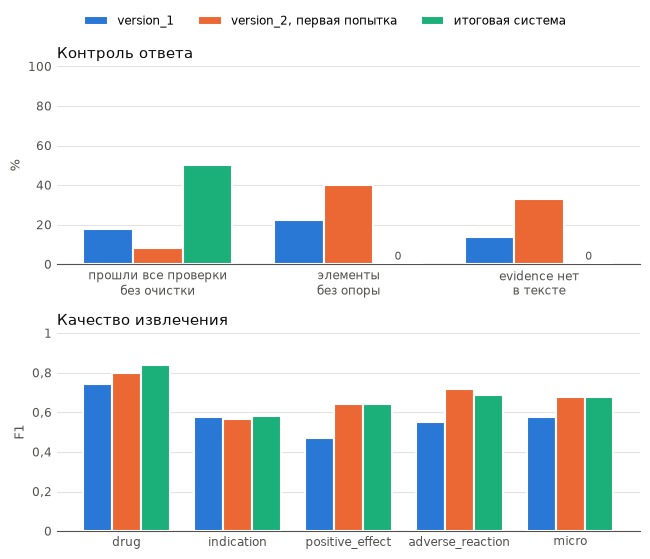

In [20]:
COLORS = {"version_1": "#2a78d6", "version_2, первая попытка": "#eb6834", "итоговая система": "#1baf7a"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
plt.rcParams["axes.formatter.use_locale"] = False


def comma(value, _):
    return f"{value:g}".replace(".", ",")


def bars(ax, groups, values, ylabel, ymax):
    width = 0.26
    for k, (name, vals) in enumerate(values.items()):
        xs = [i + (k - 1) * width for i in range(len(groups))]
        ax.bar(xs, vals, width, color=COLORS[name], edgecolor=SURFACE, linewidth=1.5, label=name, zorder=3)
        for x, v in zip(xs, vals):
            if v == 0:
                ax.text(x, ymax * 0.01, "0", ha="center", va="bottom", color=MUTED, fontsize=8)
    ax.set_xticks(range(len(groups)), groups, color=INK, fontsize=8.5)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_formatter(comma)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(colors=MUTED, length=0, labelsize=8.5)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)


control = {name: [100 * sum(r["all_checks"] for r in rows) / len(rows),
                  100 * sum(r["unsupported"] for r in rows) / max(1, sum(r["items"] for r in rows)),
                  100 * sum(r["bad_evidence"] for r in rows) / max(1, sum(r["evidence"] for r in rows))]
           for name, rows in systems.items()}
f1 = {name: [qualities[name][f][2] for f in FIELDS] + [qualities[name]["micro"][2]] for name in systems}

fig, axes = plt.subplots(2, 1, figsize=(6.6, 5.6))
bars(axes[0], ["прошли все проверки\nбез очистки", "элементы\nбез опоры", "evidence нет\nв тексте"], control, "%", 100)
axes[0].set_title("Контроль ответа", color=INK, loc="left", fontsize=10.5)
bars(axes[1], ["drug", "indication", "positive_effect", "adverse_reaction", "micro"], f1, "F1", 1)
axes[1].set_title("Качество извлечения", color=INK, loc="left", fontsize=10.5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(RESULTS / "chart.png", dpi=200, facecolor=SURFACE)
plt.show()

Таблица `results/results.csv`: по строке на отзыв и систему (version_1 и итоговая, 100 строк). В ней статус, число попыток, ошибки проверки по попыткам, пять полей ответа, удаленные элементы и фрагменты, элементы, подтвержденные по тексту, счетчики неподтвержденного, токены, время, эталон и текст отзыва.

In [21]:
def joined(values):
    return SEP.join(values)


result_rows = []
for system, raw_rows in (("version_1", raw_v1), ("final", raw_final)):
    rows = systems["version_1" if system == "version_1" else "итоговая система"]
    for raw, row in zip(raw_rows, rows):
        attempts = raw.get("attempts") or [{"errors": check_response(raw["content"], texts[raw["id"]]).errors}]
        result_rows.append({
            "id": raw["id"], "system": system, "status": row["status"] or "без проверки", "attempts": row["attempts"],
            "errors_attempt_1": joined(attempts[0]["errors"]),
            "errors_attempt_2": joined(attempts[1]["errors"]) if len(attempts) > 1 else "",
            **{f: joined(row["pred"][f]) for f in ALL_FIELDS},
            "removed_evidence": joined(raw.get("removed_evidence", [])),
            "removed_items": joined(f"{f}: {x}" for f, x in raw.get("removed_items", [])),
            "grounded_items": joined(f"{f}: {x}" for f, x in raw.get("grounded_items", [])),
            "bad_evidence": row["bad_evidence"], "unsupported": row["unsupported"], "not_in_text": row["not_in_text"],
            "input_tokens": row["input_tokens"], "output_tokens": row["output_tokens"],
            "seconds": round(row["seconds"], 2),
            **{f"gold_{f}": joined(gold_by_id[raw["id"]][f]) for f in FIELDS},
            "text": texts[raw["id"]],
        })
results = pd.DataFrame(result_rows)
results.to_csv(RESULTS / "results.csv", index=False, encoding="utf-8-sig")
results.groupby("system")["status"].value_counts()

system     status        
final      cleaned           25
           fixed_by_retry    21
           valid              4
version_1  без проверки      50
Name: count, dtype: int64

Все расхождения итоговой системы с эталоном: лишние элементы ответа (FP) и пропущенные элементы эталона (FN). Из них выбраны пять ошибок для разбора.

In [22]:
error_rows = []
for row in systems["итоговая система"]:
    for f in FIELDS:
        pred, gold = row["pred"][f], gold_by_id[row["id"]][f]
        used_p, used_g = match(pred, gold)
        error_rows += [{"id": row["id"], "field": f, "kind": "FP", "value": x}
                       for i, x in enumerate(pred) if i not in used_p]
        error_rows += [{"id": row["id"], "field": f, "kind": "FN", "value": x}
                       for j, x in enumerate(gold) if j not in used_g]
errors = pd.DataFrame(error_rows)
errors.to_csv(RESULTS / "errors_final.csv", index=False, encoding="utf-8-sig")
errors.pivot_table(index="field", columns="kind", values="value", aggfunc="count", fill_value=0)

kind,FN,FP
field,,
adverse_reaction,34,15
drug,18,1
indication,63,12
positive_effect,16,15


## 8. Пять ошибок

Случаи подобраны так, чтобы различались поле и источник ошибки. Для каждого ниже ответ, эталон и ошибки проверки по попыткам, разбор в отчете.

In [23]:
CASES = [
    ("2424525", "регистр во фрагменте не исправлен повтором, реакции потеряны; реакция из слов врача прошла проверку опоры"),
    ("6993980", "союз «А» отсеян проверкой, но показание «болезни» из общей фразы подтверждено по тексту"),
    ("978728", "деепричастие «Скинув» записано как название препарата"),
    ("2597892", "улучшение после шоколадки приписано препарату"),
    ("893416", "в эталоне RuDReC положительный эффект размечен как нежелательная реакция"),
]
raw_by_id = {r["id"]: r for r in raw_final}
for rid, kind in CASES:
    r = raw_by_id[rid]
    print(f"=== {rid}: {kind}")
    print("статус:", r["status"], "| удалено:", r["removed_items"], r["removed_evidence"],
          "| подтверждено по тексту:", r.get("grounded_items", []))
    for f in FIELDS:
        print(f"  {f}: ответ {r['result'][f]} | эталон {gold_by_id[rid][f]}")
    for a in r["attempts"]:
        for e in a["errors"]:
            print(f"  попытка {a['attempt']}: {e}")
    print()

=== 2424525: регистр во фрагменте не исправлен повтором, реакции потеряны; реакция из слов врача прошла проверку опоры
статус: cleaned | удалено: [['adverse_reaction', 'постоянная беготня'], ['adverse_reaction', 'прыжки'], ['adverse_reaction', 'куvyрки'], ['adverse_reaction', 'весь день у ребенка проходил в ритме ракеты']] ['ребенок весь день "стоит на ушах"', 'весь день у ребенка проходил в ритме ракеты', 'я в нервотрепке', 'на развитие речи результата так никакого и не было и нет'] | подтверждено по тексту: [['indication', 'отсутствие речи']]
  drug: ответ ['Когитум'] | эталон ['Когитум']
  indication: ответ ['отсутствие речи'] | эталон ['отсутствие речи']
  positive_effect: ответ [] | эталон []
  adverse_reaction: ответ ['ему стало возбуждено', 'я в нервотрепке'] | эталон ['стоит на ушах', 'угомонить невозможно', 'сон днем забыли', 'беготня по дому', 'прыжки с дивана на пол', 'кувырки', 'вымотанный']
  попытка 1: фрагмента evidence «ребенок весь день "стоит на ушах"» нет в тексте до

## 9. Выводы

1. Схема, проверка, один повтор и сборка дают ответ, в котором каждый элемент опирается на дословный фрагмент отзыва. У version_1 без проверок 14% фрагментов evidence нет в тексте, а 23% элементов не опираются на evidence.
2. Синтаксис JSON эта модель не ломает: все ответы разобрались и прошли схему. Почти вся работа проверки приходится на evidence: модель пишет первую букву фрагмента строчной, искажает слова при копировании и пересказывает.
3. Повтор с подсказкой ближайшего участка исправляет почти все недословные фрагменты (из 102 после повтора осталось 8, все отличаются регистром), но при этом модель сокращает список элементов. Сборка из обеих попыток возвращает подтвержденное.
4. Итоговая система точнее version_1 (precision 0,811 против 0,537) и по F1 не уступает первой попытке version_2 без проверок (0,679 против 0,676), а при строгих порогах совпадения лучше обеих.
5. Проверка лексическая: она гарантирует, что слова взяты из отзыва, но не смысл (отрицание, чужой опыт, причину улучшения). Это по-прежнему задача промпта, и разбор ошибок показывает, что на 4B-модели он справляется не всегда.